> __Content modified under Creative Commons Attribution license CC-BY
> 4.0, code under BSD 3-Clause License © 2020 R.C. Cooper__

# Homework

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')


## Problems [Part 1](./01_Cheers_Stats_Beers.md)

1. Gordon Moore created an empirical prediction that the rate of
semiconductors on a computer chip would double every two years. This
prediction was known as Moore's law. Gordon Moore had originally only
expected this empirical relation to hold from 1965 - 1975
[[1](https://en.wikipedia.org/wiki/Moore%27s_law),[2](https://spectrum.ieee.org/computing/hardware/gordon-moore-the-man-whose-name-means-progress)],
but semiconductor manufacturers were able to keep up with Moore's law
until 2015. 

In the folder "../data" is a comma separated value (CSV) file,
"transistor_data.csv" [taken from wikipedia
01/2020](https://en.wikipedia.org/wiki/Transistor_count#Microprocessors).

a. Use the `!head ../data/transistor_data.csv` command to look at
the top of the csv. What are the headings for the columns?

b. Load the csv into a pandas dataframe. How many missing values
(`NaN`) are
in the column with the number of transistors? What fraction are
missing?

In [3]:
!head ../data/transistor_data.csv

Processor,MOS transistor count,Date of Introduction,Designer,MOSprocess,Area
"MP944 (20-bit, 6-chip)",NaN,1970,Garrett AiResearch,?,?
"Intel 4004 (4-bit, 16-pin)",2250,1971,Intel,"10,000 nm",12 mm²
"Intel 8008 (8-bit, 18-pin)",3500,1972,Intel,"10,000 nm",14 mm²
"NEC μCOM-4 (4-bit, 42-pin)",2500,1973,NEC,"7,500 nm",?
"Intel 4040 (4-bit, 16-pin)",3000,1974,Intel,"10,000 nm",12 mm²
"Motorola 6800 (8-bit, 40-pin)",4100,1974,Motorola,"6,000 nm",16 mm²
"Intel 8080 (8-bit, 40-pin)",6000,1974,Intel,"6,000 nm",20 mm²
"TMS 1000 (4-bit, 28-pin)",8000,1974,Texas Instruments,"8,000 nm",11 mm²
"MOS Technology 6502 (8-bit, 40-pin)",4528,1975,MOS Technology,"8,000 nm",21 mm²


In [4]:
df = pd.read_csv("../data/transistor_data.csv")


In [5]:
df

,Processor,MOS transistor count,Date of Introduction,Designer,MOSprocess,Area
0,"MP944 (20-bit, 6-chip)",NaN,1970,Garrett AiResearch,?,?
1,"Intel 4004 (4-bit, 16-pin)",2.250000e+03,1971,Intel,"10,000 nm",12 mm²
2,"Intel 8008 (8-bit, 18-pin)",3.500000e+03,1972,Intel,"10,000 nm",14 mm²
3,"NEC μCOM-4 (4-bit, 42-pin)",2.500000e+03,1973,NEC,"7,500 nm",?
4,"Intel 4040 (4-bit, 16-pin)",3.000000e+03,1974,Intel,"10,000 nm",12 mm²
...,...,...,...,...,...,...
181,"Samsung Exynos 9820 (octa-core ARM64 ""mobile S...",NaN,2019,Samsung,8 nm,127 mm²
182,"AMD Ryzen 7 3700X (64-bit, SIMD, caches, I/O die)",5.990000e+09,2019,AMD,7&12 nm (TSMC),199 (74+125) mm²
183,"AMD Ryzen 9 3900X (64-bit, SIMD, caches, I/O die)",9.890000e+09,2019,AMD,7 & 12 nm (TSMC),273 mm²
184,"AMD Epyc Rome (64-bit, SIMD, caches)",3.954000e+10,2019,AMD,7 & 12 nm (TSMC),1088 mm²


In [6]:
num_transist_count_null = df['MOS transistor count'].isnull().sum()
print(f"Number of null values in 'MOS transistor count': {num_transist_count_null}")

frac_null = num_transist_count_null / len(df)
print(f"Fraction of null values in 'MOS transistor count': {frac_null:.2%}")

Number of null values in 'MOS transistor count': 7
Fraction of null values in 'MOS transistor count': 3.76%


## Problems [Part 2](./02_Seeing_Stats.md)

1. Many beers do not report the IBU of the beer because it is very
small. You may be accidentally removing whole categories of beer from
our dataset by removing rows that do not include the IBU measure. 

    a. Use the command `beers_filled = beers.fillna(0)` to clean the `beers` dataframe
    
    b. Recreate the plot "Beer ABV vs. IBU mean values by style" 
    [bubble
    plot](https://cooperrc.github.io/computational-mechanics/module_02/02_Seeing_Stats.html#bubble-chart) with `beers_filled`. What differences do you notice between the plots?

In [7]:
beers = pd.read_csv("../data/beers.csv")
beers_filled = beers.fillna(0)
beers_filled

,Unnamed: 0,abv,ibu,id,name,style,brewery_id,ounces
0,0,0.050,0.0,1436,Pub Beer,American Pale Lager,408,12.0
1,1,0.066,0.0,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,2,0.071,0.0,2264,Rise of the Phoenix,American IPA,177,12.0
3,3,0.090,0.0,2263,Sinister,American Double / Imperial IPA,177,12.0
4,4,0.075,0.0,2262,Sex and Candy,American IPA,177,12.0
...,...,...,...,...,...,...,...,...
2402,2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0
2403,2406,0.052,0.0,807,Rail Yard Ale,American Amber / Red Ale,424,12.0
2404,2407,0.055,0.0,620,B3K Black Lager,Schwarzbier,424,12.0
2405,2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0


In [8]:
beer_styles = beers_filled[['style', 'abv', 'ibu']]
beer_styles

,style,abv,ibu
0,American Pale Lager,0.050,0.0
1,American Pale Ale (APA),0.066,0.0
2,American IPA,0.071,0.0
3,American Double / Imperial IPA,0.090,0.0
4,American IPA,0.075,0.0
...,...,...,...
2402,Belgian IPA,0.067,45.0
2403,American Amber / Red Ale,0.052,0.0
2404,Schwarzbier,0.055,0.0
2405,American Pale Ale (APA),0.055,40.0


In [9]:
style_means = beer_styles.groupby('style').mean()
style_means

,abv,ibu
style,,
Abbey Single Ale,0.049000,22.000000
Altbier,0.054385,21.000000
American Adjunct Lager,0.048722,6.722222
American Amber / Red Ale,0.054000,21.015038
American Amber / Red Lager,0.047759,12.827586
...,...,...
Tripel,0.086818,8.545455
Vienna Lager,0.051050,17.050000
Wheat Ale,0.060000,24.000000


In [10]:
style_counts = beer_styles['style'].value_counts()
style_counts

style
American IPA                      424
American Pale Ale (APA)           245
American Amber / Red Ale          133
American Blonde Ale               108
American Double / Imperial IPA    105
                                 ... 
American Malt Liquor                1
Grisette                            1
Flanders Oud Bruin                  1
Braggot                             1
Low Alcohol Beer                    1
Name: count, Length: 99, dtype: int64

<Axes: title={'center': 'Beer ABV vs. IBU mean values by style'}, xlabel='abv', ylabel='ibu'>

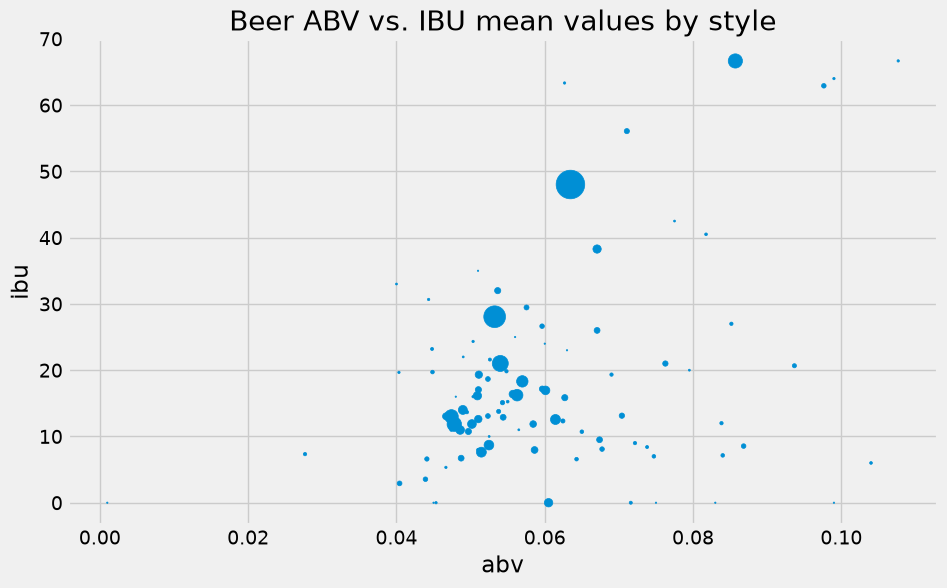

In [11]:
style_counts = style_counts.sort_index()
style_means.plot.scatter(x='abv', y='ibu', s=style_counts, figsize=(10, 6), title='Beer ABV vs. IBU mean values by style')

2. Gordon Moore created an empirical prediction that the rate of
semiconductors on a computer chip would double every two years. This
prediction was known as Moore's law. Gordon Moore had originally only
expected this empirical relation to hold from 1965 - 1975
[[1](https://en.wikipedia.org/wiki/Moore%27s_law),[2](https://spectrum.ieee.org/computing/hardware/gordon-moore-the-man-whose-name-means-progress)],
but semiconductor manufacturers were able to keep up with Moore's law
until 2015. 

    In the folder "../data" is a comma separated value (CSV) file, "transistor_data.csv" [taken from wikipedia 01/2020](https://en.wikipedia.org/wiki/Transistor_count#Microprocessors). 
    Load the csv into a pandas dataframe, it has the following headings:

    |Processor| MOS transistor count| Date of Introduction|Designer|MOSprocess|Area|
    |---|---|---|---|---|---|

    a. In the years 2017, what was the average MOS transistor count? 
    Make a boxplot of the transistor count in 2017 and find the first, second and third quartiles.

    b. Create a semilog y-axis scatter plot (i.e. `plt.semilogy`) for the 
    "Date of Introduction" vs "MOS transistor count". 
    Color the data according to the "Designer".

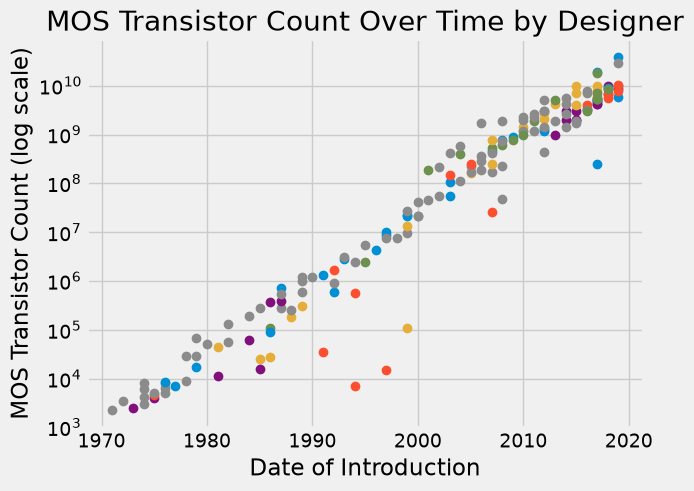

In [12]:

for designer, group in df.groupby('Designer'):
    plt.semilogy(group['Date of Introduction'], 
                 group['MOS transistor count'], 
                 marker='o', 
                 linestyle='', 
                 label=designer,
                )

plt.title('MOS Transistor Count Over Time by Designer')
plt.xlabel('Date of Introduction')
plt.ylabel('MOS Transistor Count (log scale)')
plt.show()

## Problems [Part 3](03_Linear_Regression_with_Real_Data.md)

1. There is a csv file in '../data/primary-energy-consumption-by-region.csv' that has the energy consumption of different regions of the world from 1965 until 2018 [Our world in Data](https://ourworldindata.org/energy). 
Compare the energy consumption of the United States to all of Europe. Load the data into a pandas dataframe. *Note: you can get certain rows of the data frame by specifying what you're looking for e.g. 
`EUR = dataframe[dataframe['Entity']=='Europe']` will give us all the rows from Europe's energy consumption.*

    a. Plot the total energy consumption of the United States and Europe
    
    b. Use a linear least-squares regression to find a function for the energy consumption as a function of year
    
    energy consumed = $f(t) = At+B$
    
    c. At what year would you change split the data and use two lines like you did in the 
    land temperature anomoly? Split the data and perform two linear fits. 
    
    d. What is your prediction for US energy use in 2025? How about European energy use in 2025?

In [13]:
energy = pd.read_csv('../data/primary-energy-consumption-by-region.csv')

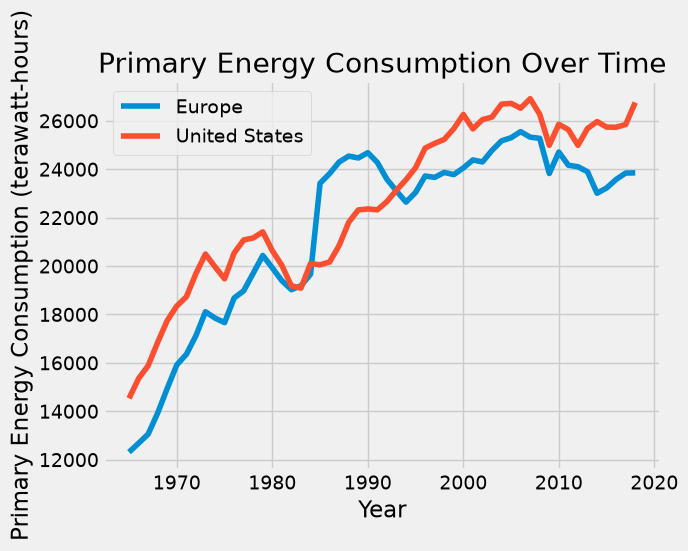

In [14]:
EUR = energy[energy['Entity'] == 'Europe']
US = energy[energy['Entity'] == 'United States']
plt.plot(EUR['Year'], EUR['Primary Energy Consumption (terawatt-hours)'], label='Europe')
plt.plot(US['Year'], US['Primary Energy Consumption (terawatt-hours)'], label='United States')
plt.title('Primary Energy Consumption Over Time')
plt.xlabel('Year')
plt.ylabel('Primary Energy Consumption (terawatt-hours)')
plt.legend()

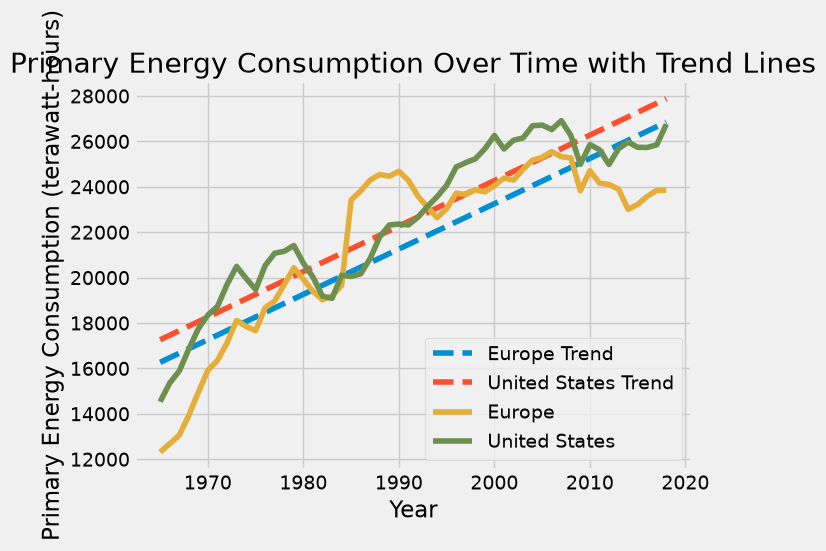

In [15]:
eur_slope, eur_intercept = np.polyfit(EUR['Year'], EUR['Primary Energy Consumption (terawatt-hours)'], 1)
us_slope, us_intercept = np.polyfit(US['Year'], US['Primary Energy Consumption (terawatt-hours)'], 1)

eur_lin = np.poly1d((eur_slope, eur_intercept))
us_lin = np.poly1d((us_slope, us_intercept))
plt.plot(EUR['Year'], eur_lin(EUR['Year']), label='Europe Trend', linestyle='--')
plt.plot(US['Year'], us_lin(US['Year']), label='United States Trend', linestyle='--')
plt.plot(EUR['Year'], EUR['Primary Energy Consumption (terawatt-hours)'], label='Europe')
plt.plot(US['Year'], US['Primary Energy Consumption (terawatt-hours)'], label='United States')
plt.title('Primary Energy Consumption Over Time with Trend Lines')
plt.xlabel('Year')
plt.ylabel('Primary Energy Consumption (terawatt-hours)')
plt.legend()


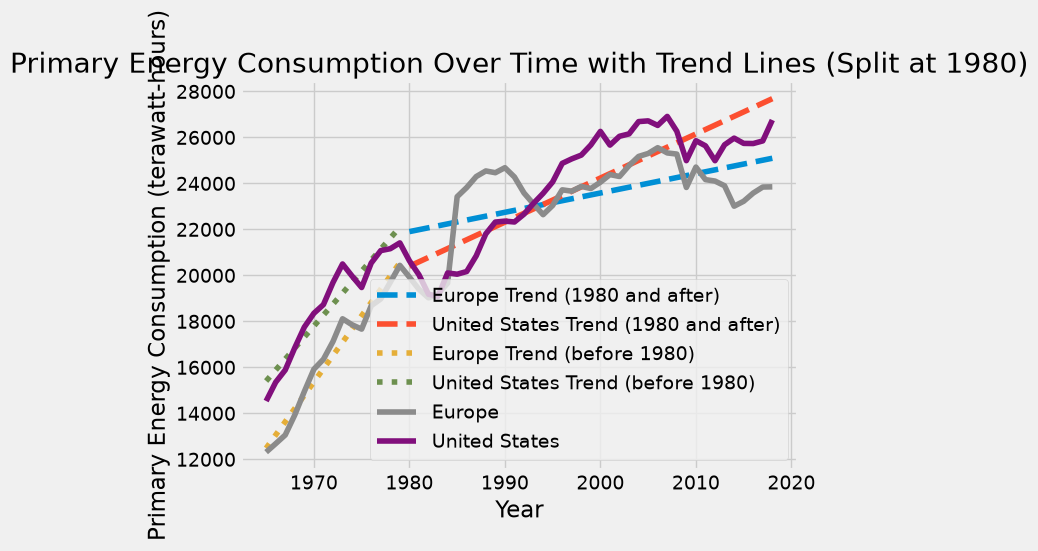

In [16]:
#Split data at 1980
EUR_80 = EUR[EUR['Year'] >= 1980]
US_80 = US[US['Year'] >= 1980]
EUR_less_80 = EUR[EUR['Year'] < 1980]
US_less_80 = US[US['Year'] < 1980]

#Fit linear regression to data after 1980
eur_slope_80, eur_intercept_80 = np.polyfit(EUR_80['Year'], EUR_80['Primary Energy Consumption (terawatt-hours)'], 1)
us_slope_80, us_intercept_80 = np.polyfit(US_80['Year'], US_80['Primary Energy Consumption (terawatt-hours)'], 1)

eur_lin_80 = np.poly1d((eur_slope_80, eur_intercept_80))
us_lin_80 = np.poly1d((us_slope_80, us_intercept_80))

#fit linear regression to data before 1980
eur_slope_less_80, eur_intercept_less_80 = np.polyfit(EUR_less_80['Year'], EUR_less_80['Primary Energy Consumption (terawatt-hours)'], 1)
us_slope_less_80, us_intercept_less_80 = np.polyfit(US_less_80['Year'], US_less_80['Primary Energy Consumption (terawatt-hours)'], 1)

eur_lin_less_80 = np.poly1d((eur_slope_less_80, eur_intercept_less_80))
us_lin_less_80 = np.poly1d((us_slope_less_80, us_intercept_less_80))

plt.plot(EUR_80['Year'], eur_lin_80(EUR_80['Year']), label='Europe Trend (1980 and after)', linestyle='--')
plt.plot(US_80['Year'], us_lin_80(US_80['Year']), label='United States Trend (1980 and after)', linestyle='--')
plt.plot(EUR_less_80['Year'], eur_lin_less_80(EUR_less_80['Year']), label='Europe Trend (before 1980)', linestyle=':')
plt.plot(US_less_80['Year'], us_lin_less_80(US_less_80['Year']), label='United States Trend (before 1980)', linestyle=':')
plt.plot(EUR['Year'], EUR['Primary Energy Consumption (terawatt-hours)'], label='Europe')
plt.plot(US['Year'], US['Primary Energy Consumption (terawatt-hours)'], label='United States')
plt.title('Primary Energy Consumption Over Time with Trend Lines (Split at 1980)')
plt.xlabel('Year')
plt.ylabel('Primary Energy Consumption (terawatt-hours)')
plt.legend()

2. You plotted Gordon Moore's empirical prediction that the rate of semiconductors on a computer chip would double every two years in [02_Seeing_Stats](./02_Seeing_Stats). This prediction was known as Moore's law. Gordon Moore had originally only expected this empirical relation to hold from 1965 - 1975 [[1](https://en.wikipedia.org/wiki/Moore%27s_law),[2](https://spectrum.ieee.org/computing/hardware/gordon-moore-the-man-whose-name-means-progress)], but semiconductor manufacturers were able to keep up with Moore's law until 2015. 

Use a linear regression to find your own historical Moore's Law.    

Use code from [02_Seeing_Stats](./02_Seeing_Stats) to plot the semilog y-axis scatter plot 
(i.e. `plt.semilogy`) for the "Date of Introduction" vs "MOS transistor count". 
Color the data according to the "Designer".

Create a linear regression for the data in the form of 

$log(transistor~count)= f(date) = A\cdot date+B$

rearranging

$transistor~count= e^{f(date)} = e^B e^{A\cdot date}$

You can perform a least-squares linear regression using the following assignments

$x_i=$ `dataframe['Date of Introduction'].values`

and

$y_i=$ as `np.log(dataframe['MOS transistor count'].values)`

a. Plot your function on the semilog y-axis scatter plot

b. What are the values of constants $A$ and $B$ for our Moore's law fit? How does this compare to Gordon Moore's prediction that MOS transistor count doubles every two years?

In [17]:
data = pd.read_csv('../data/transistor_data.csv')
data = data.dropna()
xi=data['Date of Introduction'].values
TC=data['MOS transistor count'].values
yi = np.log(TC)

In [18]:
slope, intercept = np.polyfit(xi, yi, 1)

Text(0, 0.5, 'MOS Transistor Count (log scale)')

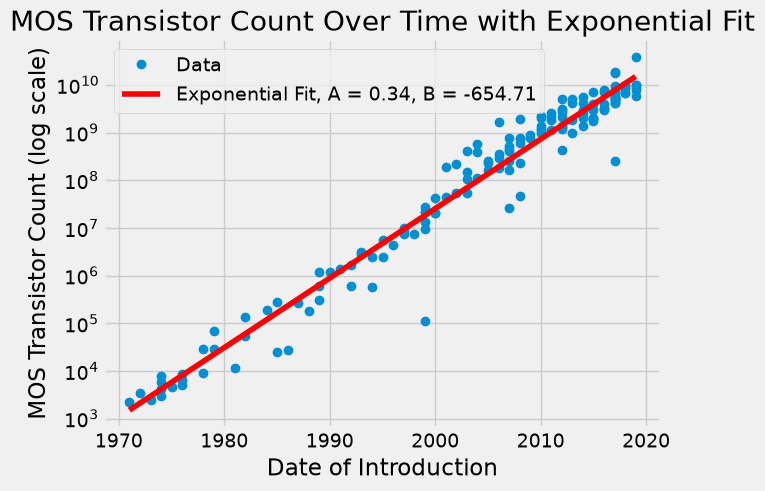

In [19]:
lin_func = np.poly1d((slope, intercept))
def exp_func(x):
    return np.exp(lin_func(x))

plt.semilogy(data['Date of Introduction'], data['MOS transistor count'], marker='o', linestyle='', label='Data')
plt.semilogy(data['Date of Introduction'], exp_func(data['Date of Introduction']), label=f'Exponential Fit, A = {slope:.2f}, B = {intercept:.2f}', color='red')
plt.title('MOS Transistor Count Over Time with Exponential Fit')
plt.legend()
plt.xlabel('Date of Introduction')
plt.ylabel('MOS Transistor Count (log scale)')

e^0.34 * e^0.34 = 1.974, Very close to Moore's original prediction of transistor counts doubling every 2 years

## Problems [Part 4](04_Stats_and_Montecarlo.md)

__1.__ [Buffon's needle problem](https://en.wikipedia.org/wiki/Buffon) is
another way to estimate the value of $\pi$ with random numbers. The goal
in this Monte Carlo estimate of $\pi$ is to create a ratio that is close
to [3.1415926...](http://www.math.com/tables/constants/pi.htm) _similar
to the example with darts points lying inside/outside a unit circle
inside a unit square._ 

![Buffon's needle for parallel
lines](https://upload.wikimedia.org/wikipedia/commons/f/f6/Buffon_needle.gif)

In this Monte Carlo estimation, you only need to know two values:
- the distance from line 0, $x = [0,~1]$
- the orientation of the needle, $\theta = [0,~2\pi]$

The y-location does not affect the outcome of crosses line 0 or not
crossing line 0. 

__a.__ Generate 100 random `x` and `theta` values _remember_ $\theta =
[0,~2\pi]$

__b.__ Calculate the x locations of the 100 needle ends e.g. $x_end = x
\pm \cos\theta$ _since length is unit 1. 

__c.__ Use 
[`np.logical_and`](https://numpy.org/doc/stable/reference/generated/numpy.logical_and.html)
to find the number of needles that have minimum $x_{end~min}<0$ and
maximum $x_{end~max}>0$. The ratio
$\frac{x_{end~min}<0~and~x_{end~max}>0}{number~of~needles} =
\frac{2}{\pi}$ _for large values of $number~of~needles$_.

__2.__ Build a random walk data set with steps between $dx = dy =
-1/2~to~1/2~m$. If 100 particles take 10 steps, calculate the number of
particles that move further than 0.5 m. 

_Bonus: Can you do the work without any `for`-loops? Change the size of
`dx` and `dy` to account for multiple particles._

In [20]:
x = np.random.random(100)
theta = np.random.random(100) * 2 * np.pi
x_end_min = x - np.cos(theta)
x_end_max = x + np.cos(theta)
ends_inside = np.logical_and((x_end_min > 0), (x_end_max < 1))
num_intersecting_segments = np.sum(ends_inside)
print(f"Number of line segments that intersect the unit interval: {np.sum(ends_inside)}")
pi = 2 / (num_intersecting_segments / len(x))
print(f"Estimated value of π: {pi}")

Number of line segments that intersect the unit interval: 63
Estimated value of π: 3.1746031746031744


In [37]:
#q2
dx = np.random.random((100, 10)) - 0.5
dy = np.random.random((100, 10)) - 0.5

particle_positions = np.zeros((100, 2))

particle_positions[:, 0] = np.cumsum(dx, axis=1)[:, -1]
particle_positions[:, 1] = np.cumsum(dy, axis=1)[:, -1]

distances = np.sqrt(np.sum(particle_positions**2, axis=1))

out_threshold = distances >= 0.5
print(f"Number of particles that moved outside the threshold: {len(out_threshold)}")


Number of particles that moved outside the threshold: 100


__3.__ 100 steel rods are going to be used to support a 1000 kg structure. The
rods will buckle when the load in any rod exceeds the [critical buckling
load](https://en.wikipedia.org/wiki/Euler%27s_critical_load)

$P_{cr}=\frac{\pi^3 Er^4}{16L^2}$

where E=200e9 Pa, r=0.01 m +/-0.001 m, and L is the 
length of the rods supporting the structure. Create a Monte
Carlo model `montecarlo_buckle` that predicts 
the mean and standard deviation of the buckling load for 100
samples with normally distributed dimensions r and L. 

```python
mean_buckle_load,std_buckle_load=\
montecarlo_buckle(E,r_mean,r_std,L,N=100)
```

__a.__ What is the mean_buckle_load and std_buckle_load for L=5 m?

__b.__ What length, L, should the beams be so that only 2.5% will 
reach the critical buckling load?

In [40]:
def montecarlo_buckle(E,r_mean,r_std,L,N=100):
    '''Generate N rods of length L with radii of r=r_mean+/-r_std
    then calculate the mean and std of the buckling loads in for the
    rod population holding a 1000-kg structure
    Arguments
    ---------
    E: Young's modulus [note: keep units consistent]
    r_mean: mean radius of the N rods holding the structure
    r_std: standard deviation of the N rods holding the structure
    L: length of the rods (or the height of the structure)
    N: number of rods holding the structure, default is N=100 rods
    Returns
    -------
    mean_buckle_load: mean buckling load of N rods under 1000*9.81/N-Newton load
    std_buckle_load: std dev buckling load of N rods under 1000*9.81/N-Newton load
    '''

    r = np.random.normal(r_mean, r_std, N)
    buckle_loads = (np.pi**3 * E * r**4) / (16 * L**2)
    mean_buckle_load = np.mean(buckle_loads)
    std_buckle_load = np.std(buckle_loads)
    
    return mean_buckle_load, std_buckle_load

mean, std = montecarlo_buckle(E=200e9, r_mean=0.01, r_std=0.001, L=5.0, N=100)
print(f"Mean buckling load: {mean:.2f} N")
print(f"Standard deviation: {std:.2f} N")

Mean buckling load: 165.33 N
Standard deviation: 57.22 N


In [41]:
P_rod = 1000 * 9.81 / 100

E = 200e9
r_mean = 0.01
r_std = 0.001

load_per_rod = 1000 * 9.81 / 100

r_critical = r_mean - 1.96 * r_std

L = np.sqrt(
    (np.pi**3 * E * r_critical**4) /
    (16 * load_per_rod)
)

print(f"Maximum rod length: {L:.2f} m")

Maximum rod length: 4.06 m
